In [20]:
#| label: imports
#| code-fold: true

import math

import geopandas as gpd
import matplotlib.pyplot as plt
from shapely import geometry as geom

import weavingspace as wsp

## Tilings are my side-gig
When I'm not doing _real_ work, a major side-project for me in the last couple of years has been developing and maintaining the [`weavingspace` python module](https://github.com/DOSull/weavingspace) for making tiled maps of multivariate data.

An intermittently rewarding aspect to this has been finding cool^[Somehow defined...] tilings and implementing them as part of the `_tiling_geometries.py` source file in `weavingspace`. I can write the function to setup a new tiling while watching television these days, because the essentials of the required code are basically the same each time. But as that file has grown to 2000+ lines of _ad hoc_ code, I've had a nagging sense that there must be a more coherent way to represent and generate tilings; if not _all_ tilings then at least those composed of regular polygons. These are the ones where I find myself making a bunch of polygons, then translating and rotating them into position to form the set of repeating elements required by `weavingspace`, and in the process reusing lots of almost-but-not-quite identical chunks of code, over and over.

Anyway, a week or so ago I came across a [_really_ smart project](https://chequesoto.info/tiling/) based around a compact, integer-based representation of such tilings. The paper explaining the work is

> Soto Sánchez JE, T Weyrich, A Medeiros e Sá, and LH de Figueiredo. 2021. [An integer representation for periodic tilings of the plane by regular polygons](https://chequesoto.info/docs/sotosanchez2021integer.pdf). _Computers & Graphics_ **95** 69-80. doi: [10.1016/j.cag.2021.01.007](https://doi.org/10.1016/j.cag.2021.01.007).

The approach has a [reference implementation in Javascript](https://chequesoto.info/tiling/)^[There is also a nice [Observable notebook implementation here](https://observablehq.com/@esperanc/synthesizing-periodic-tilings-of-the-plane).], which I had to trans-code into Python^[Not hard, and a useful learning process.] for use in `weavingspace`. The net result is that the experimental branch of `weavingspace` now offers 1500 or so regular tilings, should anyone ever want to use them.^[That many tilings creates its own issues of how to navigate and categorise them coherently, but that's a nice problem to have.]

In this post, I am here to share my (admittedly niche) enthusiasm about this approach, along with some relevant code. It's a real lesson in how the right representation can make a challenging programming problem much simpler. The code included below is lightly modified from the [reasonably well commented code in **this notebook**](https://github.com/DOSull/weavingspace/blob/324ee162b865cc3094745a5e4139e3382c60dfb3/examples/regular-tilings.ipynb) in the experimental branch of `weavingspace`. Also included there, and my own contribution is generation of the corresponding dual tilings.

### Before we start...
A couple of convenience functions for element-wise summing and multiplying vectors, along with functions to generate points, lines, and polygons for illustrative purposes along the way. It's a bit of a sledgehammer using `shapely`, and `geopandas` here for handling points, lines, and polygons, but it saves a lot of faffing around setting the aspect ratios of plots and so forth.

In [21]:
#| label: useful-functions

def vsum(*a):
  return tuple(sum(_) for _ in zip(*a, strict = True))

def vprod(*a):
  if isinstance(a[0], float|int):
    return tuple(a[0] * math.prod(_) for _ in zip(*a[1:], strict = True))
  return tuple(math.prod(_) for _ in zip(*a, strict = True))

def to_euclidean(coords):
  return sum(vprod(coords, DX)), sum(vprod(coords, DY))

def get_line(v, origin = (0, 0, 0, 0)):
  return geom.LineString([to_euclidean(origin), to_euclidean(vsum(origin, v))])

def get_point(v):
  return geom.Point(to_euclidean(v))

def get_polygon(vs):
  return geom.Polygon([get_point(v) for v in vs])

## The critical insight: we only need twelve vectors
The key insight behind the approach is that in tilings by regular 3, 4, 6, and 12 sided polygons with equal-length sides, there are only 12 possible sides, which we here consider to be unit vectors. Given a particular orientation of the tiling, every polygon side will be in of only 12 orientations, and by definition all the sides are the same length. As an example, look carefully at the tiling below.

![An example tiling from the [project website](https://chequesoto.info/tiling/)](sample-tiling.png){#fig-sample-tiling}

In spite of its complexity only 12 different tile edge orientations appear anywhere in this pattern. The pattern is dominated by edges parallel to the hexagonal tile edges, but six additional orientations appear in the blue squares that trace out the larger hexagonal structures. 

This means that using only a set of unit vectors with orientations equally spaced at 30º intervals, we can trace out all the edges in this tiling, something that turns out to be true for all tilings composed of these regular polygons.^[This bald statement is obviously not a proof, but you can trust me on this... I'm sure it's mathematically provable, but also, I have hand-coded a _lot_ of these patterns in the last couple of years: it's definitely true.]

Furthermore, we can encode the 12 vectors as 4 element integer vectors, because we only need linear combinations of the first four vectors at 0º, 30º, 60º, and 90º to the positive $x$-axis to generate any of the others.

These ideas give rise to the code below, where we have the four base vectors stored in the `DX`and `DY` tuples, and the combinations of the first four vectors to yield any of the 12 directions encoded as 4-tuples in `BASE_COORDS`.

In [22]:
#| label: the-base-vectors

DX = 1, 3 ** 0.5 / 2,          0.5, 0
DY = 0,          0.5, 3 ** 0.5 / 2, 1

# Coordinates of the twelve 30º spaced unit vectors expressed as combinations
# of 0, 30, 60, and 90º unit vectors. The first four are a single instance each
# of the four unit vectors. The other are linear combinations of these four.
BASE_COORDS = [
  ( 1,  0,  0,  0), ( 0,  1,  0,  0), ( 0,  0,  1,  0),
  ( 0,  0,  0,  1), (-1,  0,  1,  0), ( 0, -1,  0,  1),
  (-1,  0,  0,  0), ( 0, -1,  0,  0), ( 0,  0, -1,  0),
  ( 0,  0,  0, -1), ( 1,  0, -1,  0), ( 0,  1,  0, -1),
]

And here are the resulting twelve unit vectors:

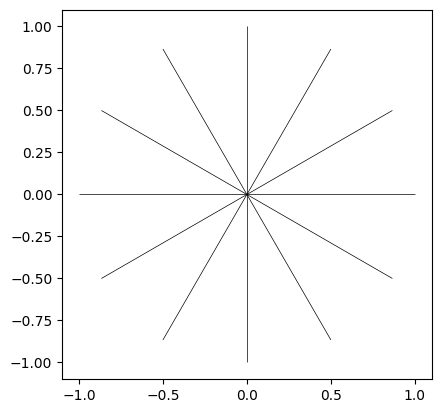

In [23]:
#| label: fig-12-unit-vectors
#| fig-cap: The 12 unit vectors
#| code-fold: true

basis = gpd.GeoSeries(
  [get_line(v) for v in BASE_COORDS])
ax = basis.plot(color = "k", lw = 0.5)

And, as an example of how they can be reduced to only combinations of the four vectors in the upper right quadrant, `BASE_COORDS[4]` being `(-1, 0, 1, 0)` tells us that the fifth unit vector, at 120º to the $x$-axis, is formed by combining the inverse (`-1`) of the first unit vector parallel to the $x$-axis, with the third unit (`1`) vector at 60º to the $x$-axis, as illustrated by the dotted red line below.

<Axes: >

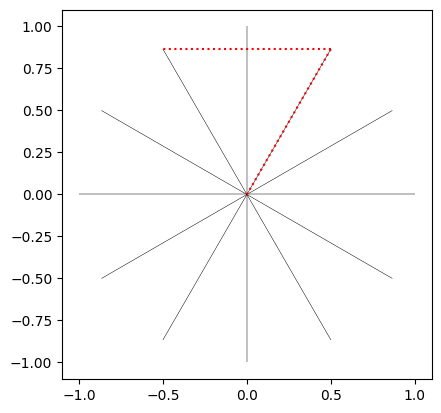

In [24]:
#| label: fig-two-unit-vectors-from-two-others
#| fig-cap: An example of a unit vector composed from two others.
#| code-fold: true

ax = basis.plot(lw = 0.35, color = "k")
gpd.GeoSeries([get_line(BASE_COORDS[2])]) \
  .plot(ax = ax, color = "r", ls = ":")
gpd.GeoSeries([get_line((-x for x in BASE_COORDS[0]), BASE_COORDS[2])]) \
  .plot(ax = ax, color = "r", ls = ":")

The sixth unit vector can be similarly encode, and the remaining six unit vectors are the inverse of the first six, derived by simply negating each coordinate in the corresponding 4-tuple (e.g., the 8th vector `(0, -1, 0, 0)` is the negative of the 2nd `(0, 1, 0, 0)`.

The paper presenting this work leans into some unnecessary mathematical complication here by referring to the 12 unit vectors as the 12 powers of the 12th complex root of unity, and using something called [_cyclotomic polynomials_](https://en.wikipedia.org/wiki/Cyclotomic_polynomial) to justify reducing the 12 vectors down to combinations of the first four. I almost stopped reading any further at that point. It certainly seems like needless obfuscation, for an approach that otherwise dramatically _simplifies_ the mathematics involved in generating these tilings!

## Representing a tiling
With this key idea in place, it turns out it is possible to capture all the information necessary to reproduce a tiling with two integer-valued 4-tuples representing the _translation vectors_ of the tiling, along with a number of integer-value 4-tuples each representing a vertex of the tiling where three or more tiles meet.

The translation vectors define the repeating area of the tiling, in effect how the repeating unit is 'copied and pasted' across the space to produce a tiling of the plane.

Because all the values involved are integers, as we'll see below, all the steps necessary to generate a tiled pattern can be precisely calculated without concerns about floating point calculations.^[The bane of my life, and of any computation requiring precision geometry.] Floating point numbers only appear at the last step of the process when we convert integer 4-tuples to points in the two-dimensional plane for plotting purposes.

In the sections below we work through the steps in the process.

### An example tiling
The values in the cell below represent a relatively simple tiling&mdash;which we will reconstruct&mdash;in a surprisingly minimal way. The tiling's translation vectors are `t1` and `t2`, and its vertices are listed in `vertices`, both in the integer 4-tuple representation of described above.

In [25]:
#| label: fig-minimal-representation

t1 = (2, 1, -2, -1)
t2 = (0, 1, 2, 0)
vertices = (
  (0, 0, 0, 0), (1, 0, 0, 0), (1, 1, -1, -1),
  (1, 0, 1, 0), (1, 1, 0, -1), (1, 1, 1, -1),
  (1, 1, 1, 0), (2, 1, 0, -1)
)

The figure below shows the translation vectors, along with the eight vertices required to build the tiling, and also the repeating area defined by the translation vectors

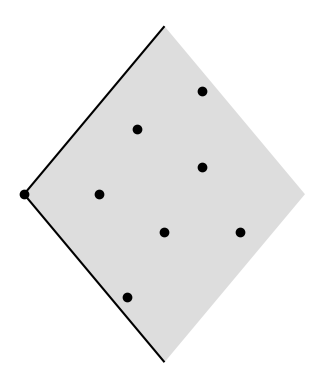

In [26]:
#| label: fig-basic-representation
#| fig-cap: The translation vectors and vertices of a simple tiling.
#| code-fold: true

base_unit = gpd.GeoSeries([get_polygon([
  [0, 0, 0, 0], t1, vsum(t1, t2), t2
])])

ax = base_unit.plot(fc = "#dddddd")
gpd.GeoSeries([get_line(t1)]).plot(ax = ax, color = "k")
gpd.GeoSeries([get_line(t2)]).plot(ax = ax, color = "k")
gpd.GeoSeries([get_point(v) for v in vertices]).plot(ax = ax, color = "k")
ax.set_axis_off()

There's enough information contained in this minimal representation to enable construction of a complete tiling.

### The local 'patch'
All the information required is not _directly_ available in the four vertices. We have to construct a local 'patch' by copying and pasting the vertices by the translation vectors, one step in all eight possible directions. The function `get_patch()` below does the work, returning the local patch vertices as a `set`. Notably, all the calculations are integer-based.

In [27]:
#| label: function-get-patch

def get_patch(vs, t1, t2):
  patch = set()
  for k1 in range(-1, 2):
    for k2 in range(-1, 2):
      for v in vs:
        hashcode = vsum(v, vprod(k1, t1), vprod(k2, t2))
        patch.add(hashcode)
  return patch

Using this we can see the four vertices in the context of a repeated pattern.

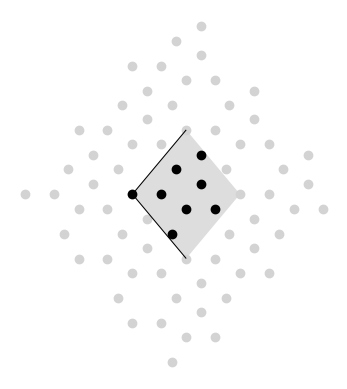

In [28]:
#| label: fig-plot-patch
#| code-fold: true
#| fig-cap: The tiling vertices in the local patch context.

patch = get_patch(vertices, t1, t2)

ax = base_unit.plot(fc = "#dddddd")
gpd.GeoSeries([get_line(t1)]).plot(ax = ax, color = "k", lw = 0.75)
gpd.GeoSeries([get_line(t2)]).plot(ax = ax, color = "k", lw = 0.75)
gpd.GeoSeries([get_point(v) for v in patch]) \
  .plot(ax = ax, color = "lightgrey")
gpd.GeoSeries([get_point(v) for v in vertices]) \
  .plot(ax = ax, color = "k")
ax.set_axis_off()

### Constructing vertex 'stars'
Next, we check for each vertex which other vertices in the local patch are neighbours along a tile edge. If two vertices are separated by one of the 12 unit vectors then they _must_ be neighbours, since all edges in the tiling are one of those vectors, and again, we can carry out this test using only precise integer arithmetic.

The function `get_star()` below iterates over all 12 vectors checking if when added to the vertex being tested they reach another vertex in the local patch. If so, the index position of the vector is appended to the 'star' (it will become clear why it's call a star in a moment). 

In [29]:
#| label: get-star

def get_star(v, patch):
  star = []
  for k in range(12):
    candidate = vsum(v, BASE_COORDS[k])
    if candidate in patch:
      star.append(k)
  return star

The figure below shows the combined 'stars' of all four vertices, and highlights one of them in red.

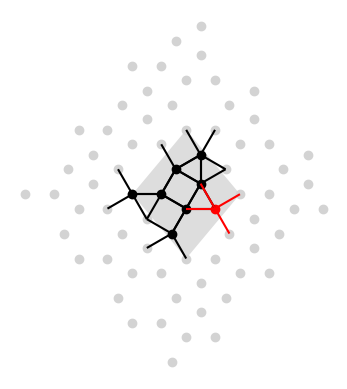

In [38]:
#| label: fig-plot-stars
#| fig-cap: The 'stars' of the tiling's vertices, with one highlighted in red.
#| code-fold: true

ax = base_unit.plot(fc = "#dddddd")
gpd.GeoSeries([get_point(v) for v in patch]) \
  .plot(ax = ax, color = "lightgrey")
stars = []
for i, v in enumerate(vertices):
  stars.append(get_star(v, patch))
  color = "r" if i == len(vertices) - 1 else "k"
  gpd.GeoSeries([get_point(v)]).plot(ax = ax, color = color)
  gpd.GeoSeries([get_line(BASE_COORDS[i], v) for i in stars[-1]]) \
    .plot(ax = ax, color = color)
  ax.set_axis_off()

Note that stars are stored only as integers, not complex vectors:

In [39]:
stars

[[0, 4, 7, 10],
 [2, 6, 8, 11],
 [2, 5, 7, 10],
 [1, 4, 8, 11],
 [0, 2, 5, 8],
 [1, 3, 5, 8, 10],
 [2, 4, 7, 9, 11],
 [1, 4, 6, 10]]

### Constructing tile polygons from stars
The sequence of gaps between the integers in each vertex star tells us the angle at that position, which in turn tells us which kind of polygon it is. A gap of 2 corresponds to 60º and hence a triangle, 3 is 90º hence a square, 4 is 120º hence a hexagon, and 5 is 150º hence a dodecagon.

The `gap_to_n_sides()` function does this translation.

In [40]:
#| label: gap-to-n-sides

def gap_to_n_sides(gap):
  k = abs(gap)
  return ( 3 if k == 2
     else  4 if k == 3
     else  6 if k == 4
     else 12 if k == 5
     else gap_to_n_sides(12 - k) if k > 6
     else None)

We're almost there now.

The functions in the cell below assemble a list of all the tiles (`faces`) at every vertex. Again, we don't have to do any floating point calculations. Each face is a sequence of integer 4-tuples, only converted to floating point when we need to plot them.

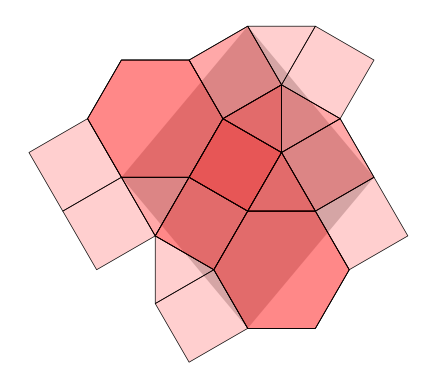

In [45]:
#| label: fig-all-star-tiles
#| fig-cap: All the tiles at every star of the tiling with duplicates and tiles outside the repeating unit area apparent.

def get_face(v, heading, n_sides):
  J = 12 // n_sides
  face = [v]
  for angle in range(0, 12, J):
    p = vsum(face[-1], BASE_COORDS[(heading + angle) % 12])
    face.append(p)
  return face[:-1]

def star_to_faces(star, v):
  faces = []
  for left, right in zip(star, [*star[1:], star[0]], strict = True):
    n = gap_to_n_sides((right - left) % 12)
    faces.append(get_face(v, left, n))
  return faces

faces = []
for star, v in zip(stars, vertices):
  faces.extend(star_to_faces(star, v))
ax = base_unit.plot(fc = "#cccccc")
gpd.GeoSeries([get_polygon(f) for f in faces]) \
  .plot(ax = ax, fc = "#ff000030", ec = "k", lw = 0.5)
# gpd.GeoSeries(get_line(t1)).plot(ax = ax, color = "k")
# gpd.GeoSeries(get_line(t2)).plot(ax = ax, color = "k")
ax.set_axis_off()

As can be seen in the picture, there are a couple of remaining issues. First, because some tiles are incident at more than one of the vertices, we get multiple copies of them. Second, some tiles clearly lie outside the repeating unit, or mostly outside it, and are not required to generate the repeating tiled pattern. We resolve those issues in the next section.

### Only constructing the tiles we need
To resolve these issues, as we build the minimal set of tiles we check to see (i) if we've already generated the tile in question, and (ii) if its centroid lies inside the repeating area defined by the translation vectors.

Taking the latter first, a couple more functions are required. This involves some simple matrix mathematics. I'll spare you the details, but in essence we are checking if a given point lies in the space defined by any combination $x\mathbf{t}_1 + y\mathbf{t}_2$ such that both $x$ and $y$ are in the range 0 to 1.^[This _is_ a floating point test and given all my experiences with `weavingspace` it makes me nervous!]

In [46]:
#| label: change-base-and-is-in-parallelogram

def change_base(a, t1, t2):
  det = t1[0] * t2[1] - t1[1] * t2[0]
  d1 =   a[0] * t2[1] -  a[1] * t2[0]
  d2 =  t1[0] *  a[1] - t1[1] *  a[0]
  return d1 / det, d2 / det

def is_in_parallelogram(p, t1, t2):
  U = change_base(to_euclidean(p), to_euclidean(t1), to_euclidean(t2))
  return ((U[0] >= -1e-4) and (U[0] < 1 - 1e-4) and 
          (U[1] >= -1e-4) and (U[1] < 1 - 1e-4))

The other aspect to this step as set out in the cell below, that may seem a little odd, is that we keep track of already added tiles, by storing already added tile centroids _scaled by a factor of six_. This ensures that all tile centroids have integer coordinates, which makes checking and comparing them more reliable. We do have to remember that they have been scaled by six when checking if they fall in the translation vector parallelogram, but that's easy enough to do.

All this has been put together in the code cell below, where we loop over the vertices, get their stars, get the polygons around the stars, and retain those polygons only if we haven't already retained them _and_ their centroid lies inside the translation vectors parallelogram.

In [47]:
tiles = []
centroids = set()
for vertex in vertices:
  star = get_star(vertex, patch)
  faces = star_to_faces(star, vertex)
  for face in faces:
    # scale by 6 to ensure integer 4-tuple
    # and remember to downscale below for testing
    centroid = tuple(int(6 * p / len(face)) for p in vsum(*face))
    if centroid not in centroids and \
        is_in_parallelogram(vprod(1/6, centroid), t1, t2):
      centroids.add(centroid)
      tiles.append(face)

And here's the result.

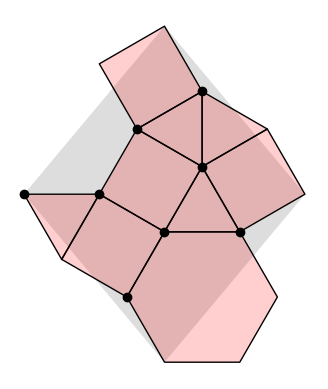

In [48]:
ax = base_unit.plot(fc = "#dddddd")
gpd.GeoSeries([get_polygon(tile) for tile in tiles]) \
  .plot(ax = ax, fc = "#ff000030", ec = "k")
gpd.GeoSeries([get_point(v) for v in vertices]) \
  .plot(ax = ax, color = "k")
ax.set_axis_off()

## Using all this to make tilings
I'm doing all this to extend the range of tilings available in `weavingspace`, so it's necessary for my purposes to convert this set of tiles to a `weavingspace.TileUnit`. Here's how that works in practice (without getting into too much of the nitty-gritty).

<Axes: >

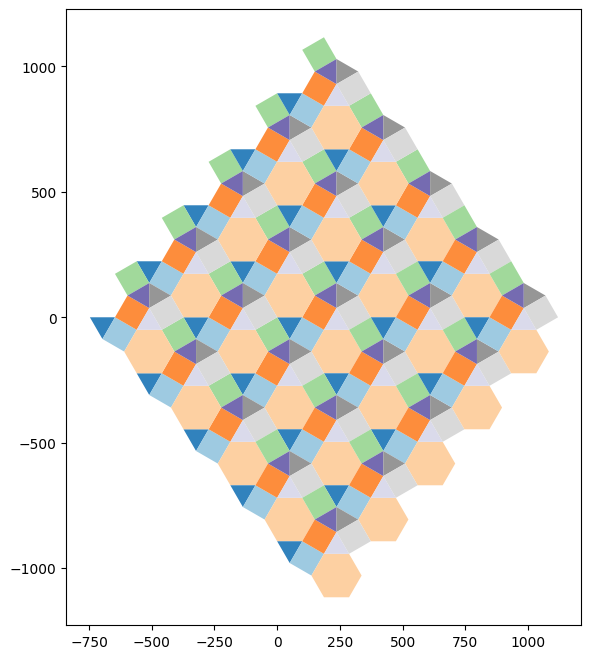

In [63]:
#| label: fig-weavingspace-33434
#| fig-cap: The 3.3.4.3.4 tiling as generated by `weavingspace` using this approach

t = wsp.TileUnit()
t.tiles = gpd.GeoDataFrame(
  geometry = gpd.GeoSeries(
    gpd.GeoSeries([get_polygon(tile) for tile in tiles])),
  data = {"tile_id": list("abcdefghi")}, crs = 3857)
t.setup_vectors(to_euclidean(t1), to_euclidean(t2))
t.prototile = t.get_prototile_from_vectors()
t._setup_regularised_prototile(True)
t = t.transform_scale(100, 100)

t.plot(r = 2, r_alpha = 1, cmap = "tab20c",
  show_prototile = False, show_reg_prototile = False, show_ids = False)

So far, this code remains in the experimental branch of `weavingspace`. 

Three example tilings from the catalogues produced by the Soto Sanchéz team, alongside their [_dual tilings_](https://mathworld.wolfram.com/DualTessellation.html) generated with the experimental `weavingspace` code are shown below. I have implemented determination of the dual tilings in keeping with the integer 4-tuples approach.

::: {#fig-weavingspace-tilings layout-ncol=2}

![](tiling-1.png)

![](tiling-2.png)

![](tiling-3.png)

![](tiling-4.png)

![](tiling-5.png)

![](tiling-6.png)

Three tilings and their duals generated in `weavingspace` using this approach.
:::

## Concluding thoughts
As an exercise in the triumph of a data structure and algorithms over doing things in more immediately obvious ways (as mentioned at the top "making a bunch of polygons, then translating and rotating them into position") this approach takes some beating.

There is something deeply pleasing (to me at least) about how all the pieces of this approach come together. It's particularly nice not dealing with floating point calculations and the seemingly never ending edge cases they produce. Even in the context of the `weavinspace` project where many of the hundreds of tilings this method makes available will likely never be used, I've found working through the process of putting this code together very rewarding. I hope this outline of how it works has been an interesting read.